In [2]:
from pathlib import Path
import zipfile
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
zip_path = Path("archive.zip")
import zipfile

extract_path = Path("the-kitti-pose-estimation-dataset")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete")


Extraction complete


In [4]:
columns = [
    "lat", "lon", "alt",
    "roll", "pitch", "yaw",
    "vn", "ve", "vf", "vl", "vu",
    "ax", "ay", "az",
    "af", "al", "au",
    "wx", "wy", "wz",
    "wf", "wl", "wu",
    "pos_accuracy", "vel_accuracy",
    "navstat", "numsats",
    "posmode", "velmode", "orimode"
]

In [5]:
data_files = list(extract_path.glob("**/oxts/data/*.txt"))
records = []

for file in data_files:
    line = file.read_text(encoding="utf-8").strip()
    values = line.split()

    drive = file.parent.parent.name
    date = file.parent.parent.parent.name

    records.append({
        "date": date,
        "drive": drive,
        "frame": file.stem,
        **dict(zip(columns, values))
    })

df = pd.DataFrame(records)


In [6]:
numeric_cols = [
    "lat", "lon", "alt",
    "roll", "pitch", "yaw",
    "vn", "ve", "vf", "vl", "vu",
    "ax", "ay", "az",
    "af", "al", "au",
    "wx", "wy", "wz",
    "wf", "wl", "wu",
    "pos_accuracy", "vel_accuracy"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [7]:
int_cols = [
    "navstat",
    "numsats",
    "posmode",
    "velmode",
    "orimode"
]

for col in int_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

In [8]:
print("Number of data files:", len(data_files))
print("Shape:", df.shape)
df.head()

Number of data files: 1436
Shape: (1436, 33)


,date,drive,frame,lat,lon,alt,roll,pitch,yaw,vn,...,wf,wl,wu,pos_accuracy,vel_accuracy,navstat,numsats,posmode,velmode,orimode
0,2011_09_26_drive_0001_sync,oxts,0000000000,49.015004,8.434297,116.430328,0.035752,0.009030,-2.608707,-6.811441,...,0.008902,-0.022495,-0.018809,0.027659,0.012728,4,11,6,6,6
1,2011_09_26_drive_0001_sync,oxts,0000000001,49.014997,8.434280,116.432274,0.036453,0.008009,-2.611005,-6.769916,...,0.004393,-0.012614,-0.021891,0.027659,0.012728,4,11,6,6,6
2,2011_09_26_drive_0001_sync,oxts,0000000002,49.014991,8.434265,116.435295,0.035908,0.006461,-2.613314,-6.731519,...,-0.005684,-0.016039,-0.023276,0.027659,0.012728,4,11,6,6,6
3,2011_09_26_drive_0001_sync,oxts,0000000003,49.014985,8.434249,116.440720,0.035565,0.005031,-2.615904,-6.684933,...,-0.005634,-0.013817,-0.024773,0.027659,0.012728,4,11,6,6,6
4,2011_09_26_drive_0001_sync,oxts,0000000004,49.014979,8.434233,116.447853,0.034299,0.006470,-2.618804,-6.634209,...,-0.009492,0.011586,-0.026827,0.027659,0.012728,4,11,6,6,6


In [9]:
df.columns

Index(['date', 'drive', 'frame', 'lat', 'lon', 'alt', 'roll', 'pitch', 'yaw',
       'vn', 've', 'vf', 'vl', 'vu', 'ax', 'ay', 'az', 'af', 'al', 'au', 'wx',
       'wy', 'wz', 'wf', 'wl', 'wu', 'pos_accuracy', 'vel_accuracy', 'navstat',
       'numsats', 'posmode', 'velmode', 'orimode'],
      dtype='str')

In [10]:
df.dtypes

date                str
drive               str
frame               str
lat             float64
lon             float64
alt             float64
roll            float64
pitch           float64
yaw             float64
vn              float64
ve              float64
vf              float64
vl              float64
vu              float64
ax              float64
ay              float64
az              float64
af              float64
al              float64
au              float64
wx              float64
wy              float64
wz              float64
wf              float64
wl              float64
wu              float64
pos_accuracy    float64
vel_accuracy    float64
navstat           Int64
numsats           Int64
posmode           Int64
velmode           Int64
orimode           Int64
dtype: object

In [11]:
df.isnull().sum()

date            0
drive           0
frame           0
lat             0
lon             0
alt             0
roll            0
pitch           0
yaw             0
vn              0
ve              0
vf              0
vl              0
vu              0
ax              0
ay              0
az              0
af              0
al              0
au              0
wx              0
wy              0
wz              0
wf              0
wl              0
wu              0
pos_accuracy    0
vel_accuracy    0
navstat         0
numsats         0
posmode         0
velmode         0
orimode         0
dtype: int64

In [12]:
df.describe()

,lat,lon,alt,roll,pitch,yaw,vn,ve,vf,vl,...,wf,wl,wu,pos_accuracy,vel_accuracy,navstat,numsats,posmode,velmode,orimode
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,...,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.0,1436.0,1436.0,1436.0,1436.0
mean,49.017197,8.437196,114.579432,0.013958,0.009426,0.615913,2.678825,0.044857,6.894826,0.005537,...,0.000037,0.000139,-0.001191,0.185422,0.026120,4.0,10.619777,4.839833,4.779944,3.052925
std,0.005805,0.014311,1.095921,0.021078,0.005472,1.624721,5.369995,6.321270,5.329600,0.059601,...,0.014298,0.016101,0.101884,0.142945,0.014344,0.0,2.392555,1.047699,1.217887,2.990342
min,49.010620,8.339749,112.460381,-0.028953,-0.012649,-3.015450,-6.811441,-11.657424,-0.034178,-0.184883,...,-0.066640,-0.074193,-0.523618,0.019105,0.010630,4.0,2.0,-1.0,-1.0,-1.0
25%,49.011377,8.434276,113.846539,-0.012201,0.005952,-0.377670,-1.150214,-3.984711,0.069343,-0.019109,...,-0.005624,-0.005334,-0.007319,0.028425,0.012728,4.0,9.0,4.0,4.0,0.0
50%,49.015548,8.438831,114.819767,0.020700,0.009733,1.286174,0.012982,-0.004946,7.352626,-0.001811,...,0.000066,-0.000054,0.000122,0.211518,0.029698,4.0,11.0,5.0,5.0,6.0
75%,49.025527,8.448535,115.190065,0.031288,0.013428,1.880275,8.099176,2.778252,11.562268,0.027819,...,0.005016,0.005220,0.010295,0.335601,0.033422,4.0,13.0,6.0,6.0,6.0
max,49.030861,8.448614,116.490036,0.052650,0.032094,2.689510,12.485973,11.843516,15.599220,0.219123,...,0.066568,0.098503,0.416318,0.519609,0.077897,4.0,14.0,6.0,6.0,6.0


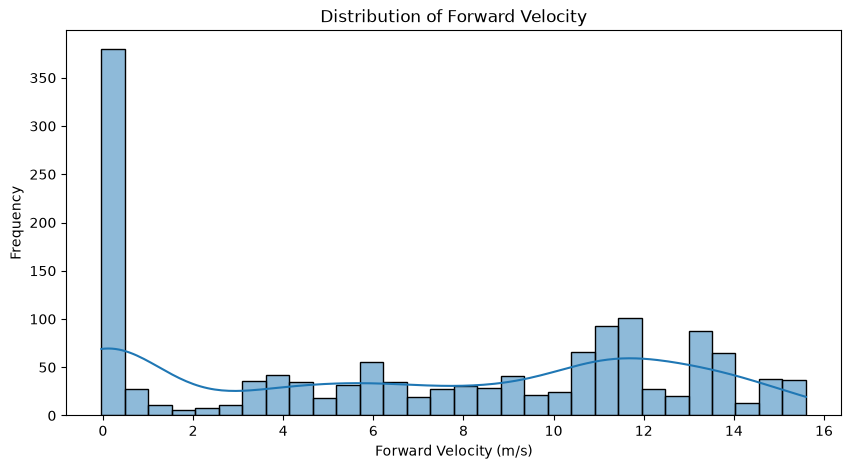

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(df["vf"], bins=30, kde=True)

plt.title("Distribution of Forward Velocity")
plt.xlabel("Forward Velocity (m/s)")
plt.ylabel("Frequency")

plt.show()

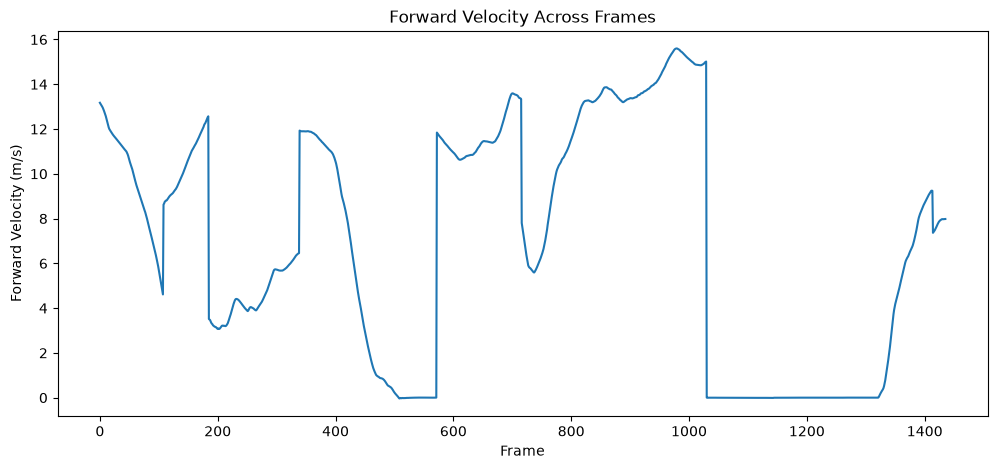

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(df["vf"])

plt.title("Forward Velocity Across Frames")
plt.xlabel("Frame")
plt.ylabel("Forward Velocity (m/s)")

plt.show()

In [15]:
df["date"].unique()

<ArrowStringArray>
['2011_09_26_drive_0001_sync', '2011_09_26_drive_0002_sync',
 '2011_09_26_drive_0005_sync', '2011_09_26_drive_0011_sync',
 '2011_09_26_drive_0013_sync', '2011_09_26_drive_0014_sync',
 '2011_09_26_drive_0017_sync', '2011_09_26_drive_0018_sync',
 '2011_09_26_drive_0048_sync']
Length: 9, dtype: str

In [16]:
df["date"].value_counts()

date
2011_09_26_drive_0014_sync    314
2011_09_26_drive_0018_sync    270
2011_09_26_drive_0011_sync    233
2011_09_26_drive_0005_sync    154
2011_09_26_drive_0013_sync    144
2011_09_26_drive_0017_sync    114
2011_09_26_drive_0001_sync    108
2011_09_26_drive_0002_sync     77
2011_09_26_drive_0048_sync     22
Name: count, dtype: int64

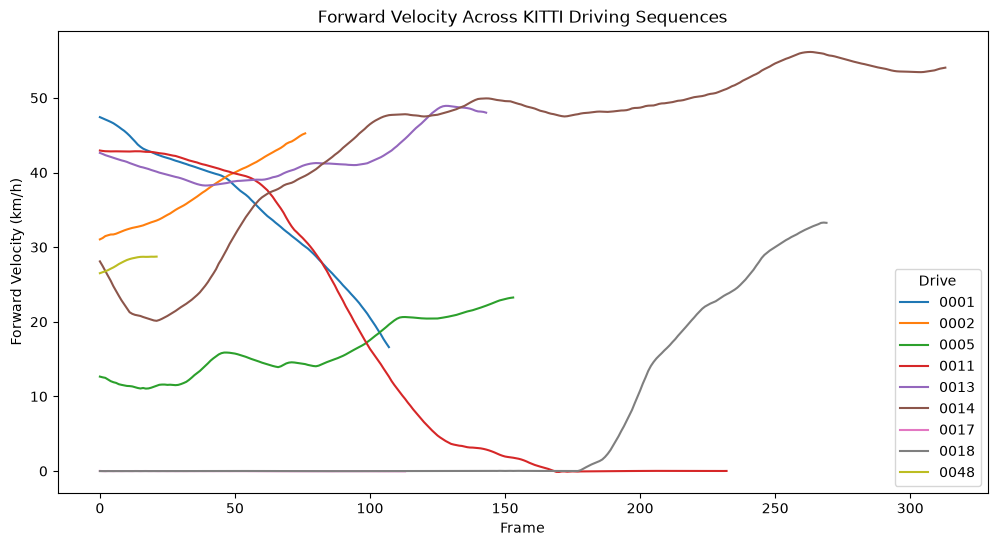

In [17]:
plt.figure(figsize=(12, 6))

for sequence, group in df.groupby("date"):
    plt.plot(
        group["frame"].astype(int),
        group["vf"] * 3.6,
        label=sequence.replace("2011_09_26_drive_", "").replace("_sync", "")
    )

plt.title("Forward Velocity Across KITTI Driving Sequences")
plt.xlabel("Frame")
plt.ylabel("Forward Velocity (km/h)")
plt.legend(title="Drive")
plt.show()

In [ ]:
from pathlib import Path

figures_dir = Path("eda/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

print("Figure output folder:", figures_dir.resolve()) 

In [18]:
from pathlib import Path

figures_dir = Path("eda/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

print("Figure output folder:", figures_dir.resolve())

Figure output folder: C:\Users\satya\KITTI EDA\eda\figures


In [19]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

print("Number of numerical columns:", len(numeric_cols))
print(numeric_cols)

Number of numerical columns: 30
['lat', 'lon', 'alt', 'roll', 'pitch', 'yaw', 'vn', 've', 'vf', 'vl', 'vu', 'ax', 'ay', 'az', 'af', 'al', 'au', 'wx', 'wy', 'wz', 'wf', 'wl', 'wu', 'pos_accuracy', 'vel_accuracy', 'navstat', 'numsats', 'posmode', 'velmode', 'orimode']


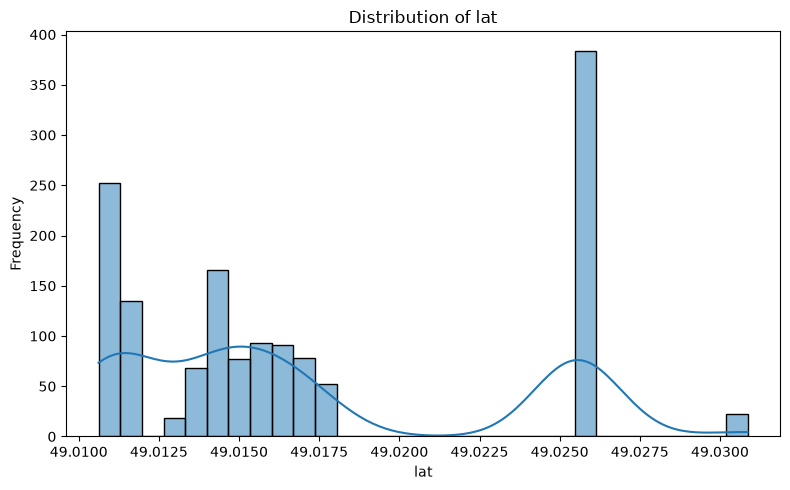

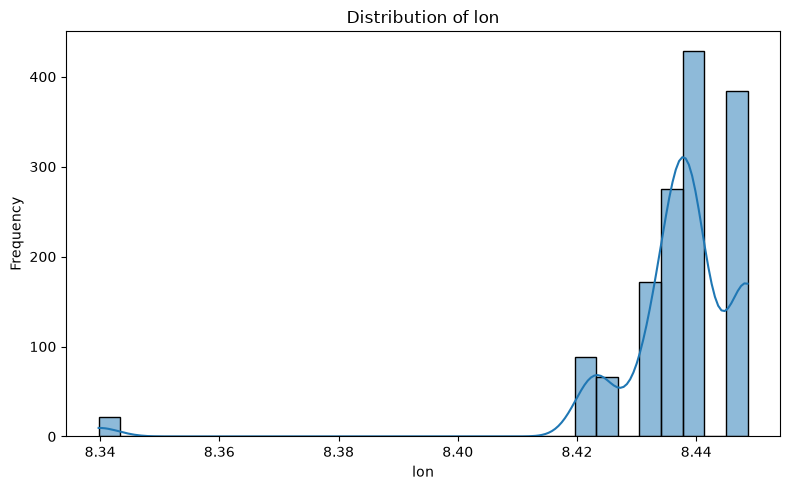

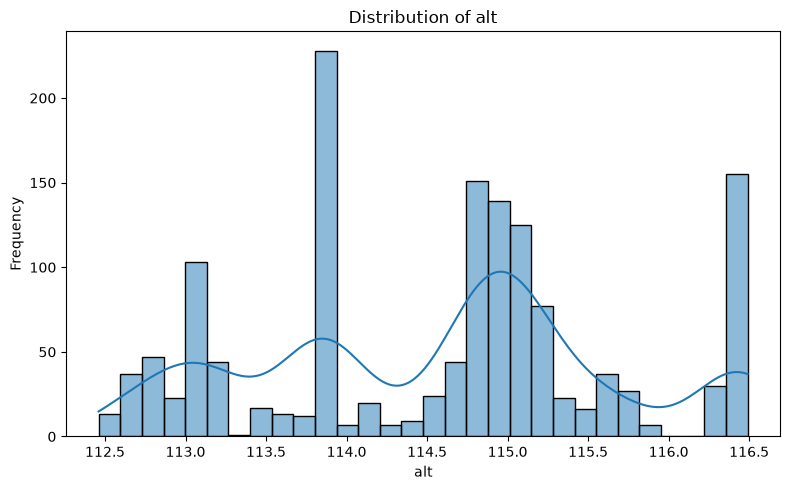

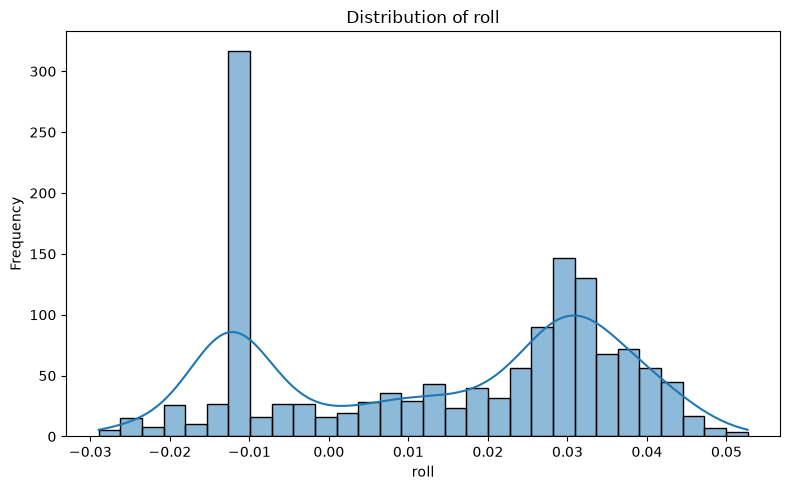

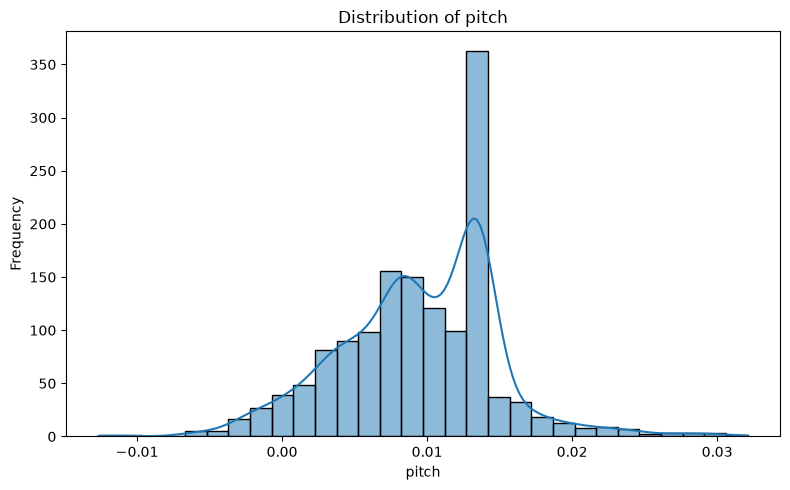

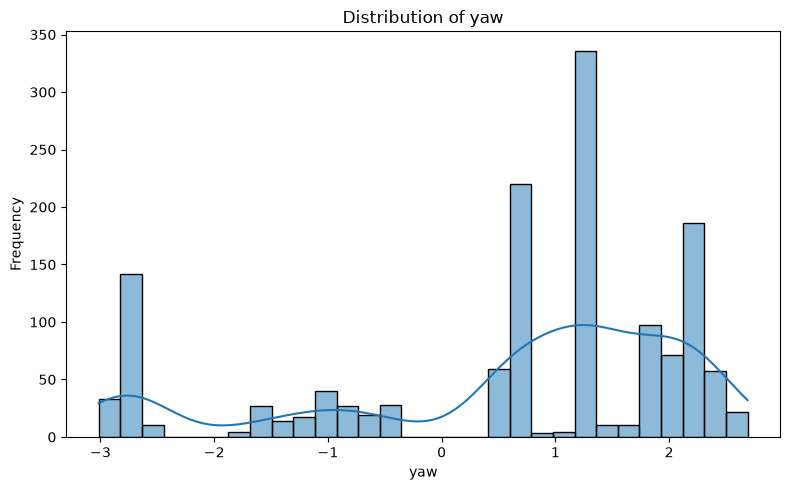

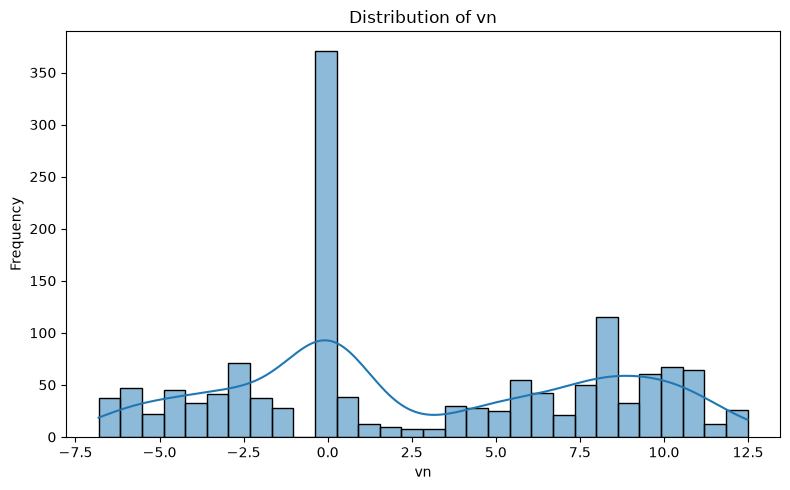

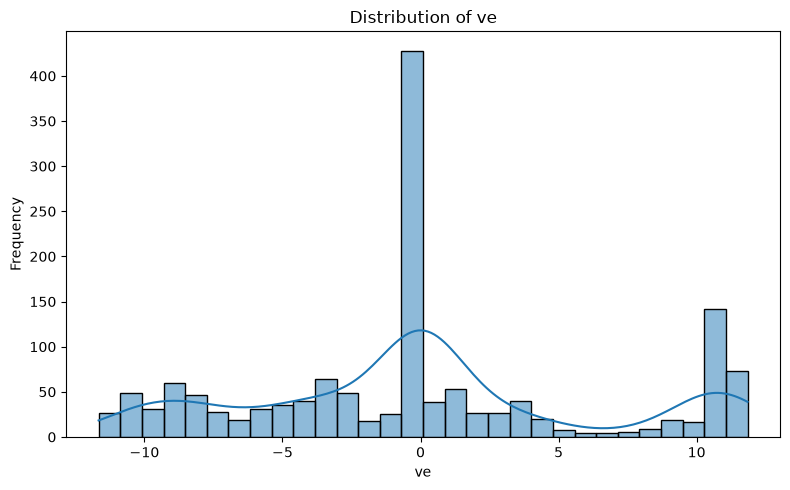

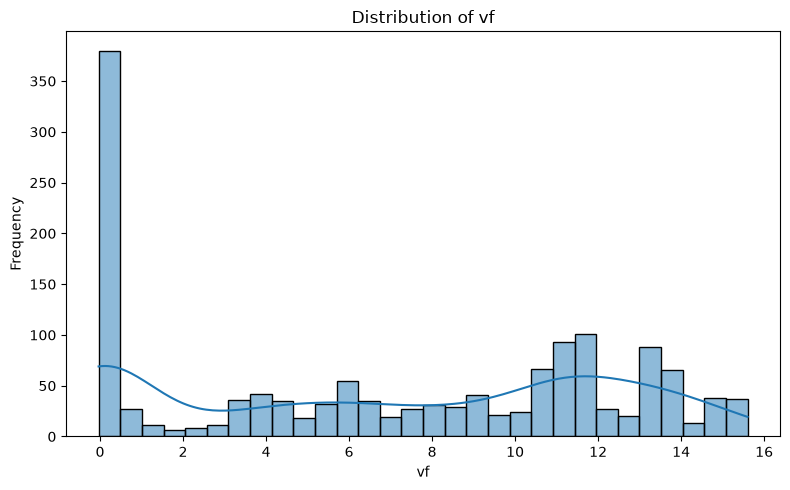

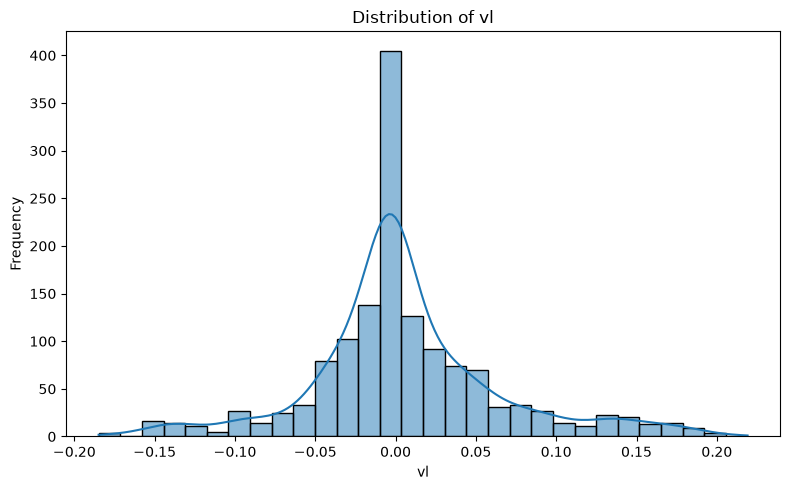

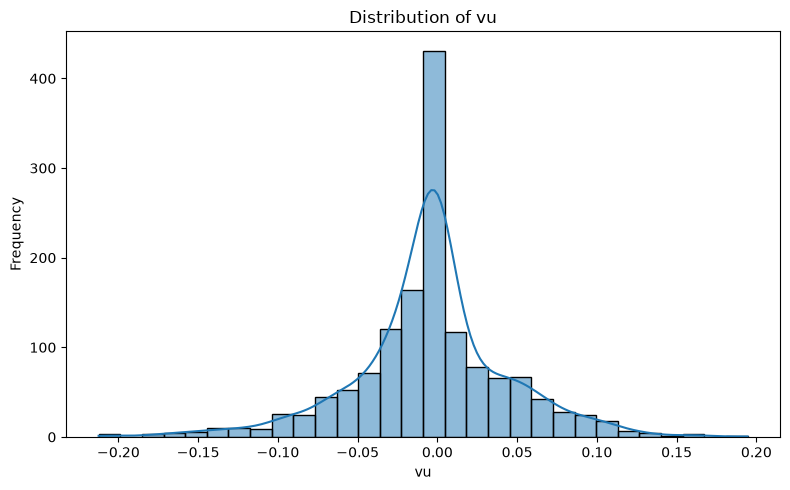

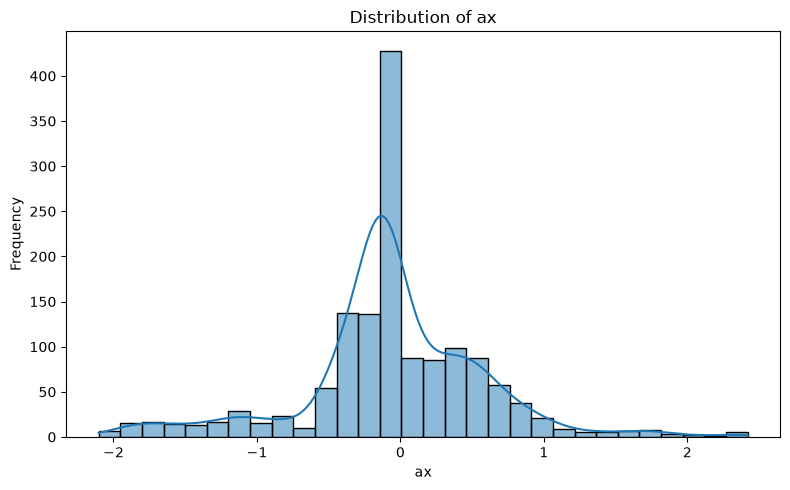

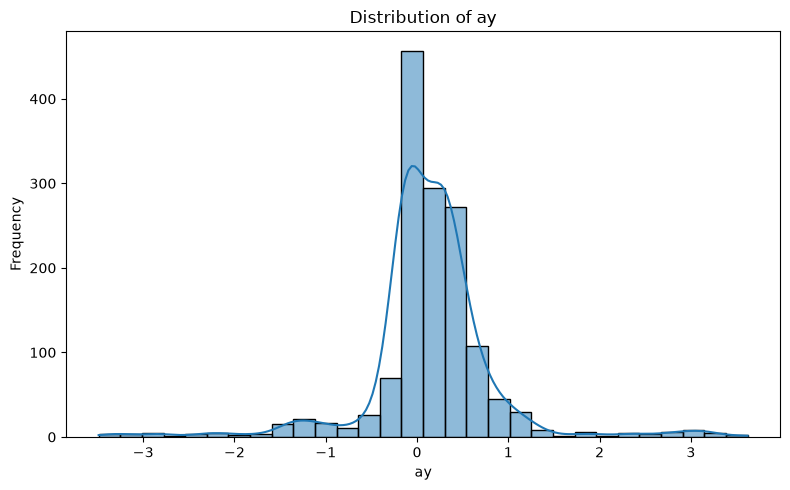

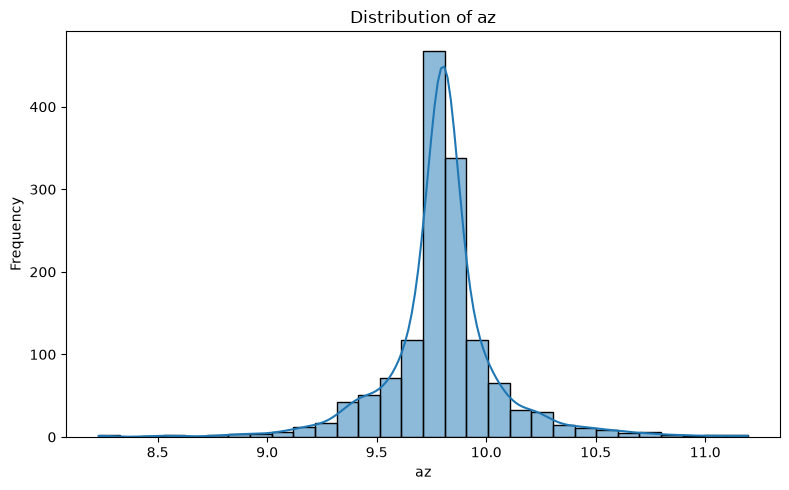

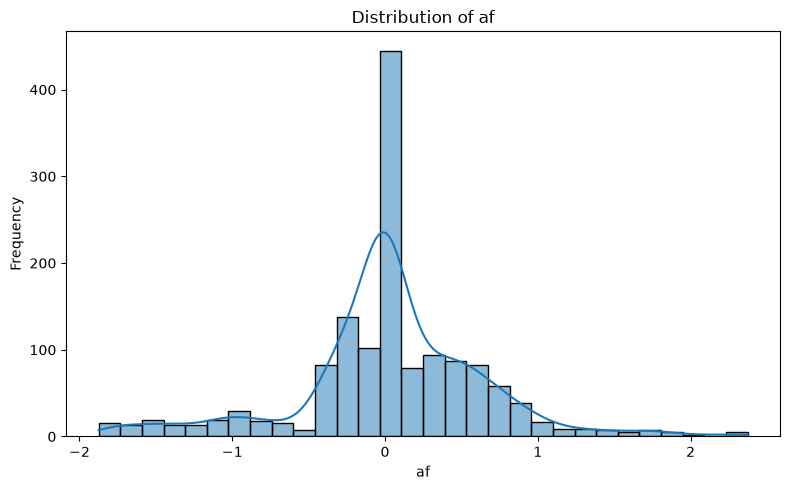

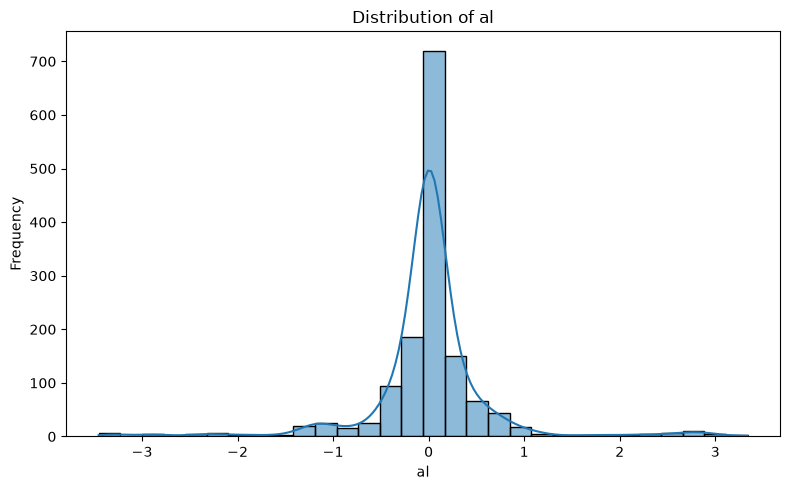

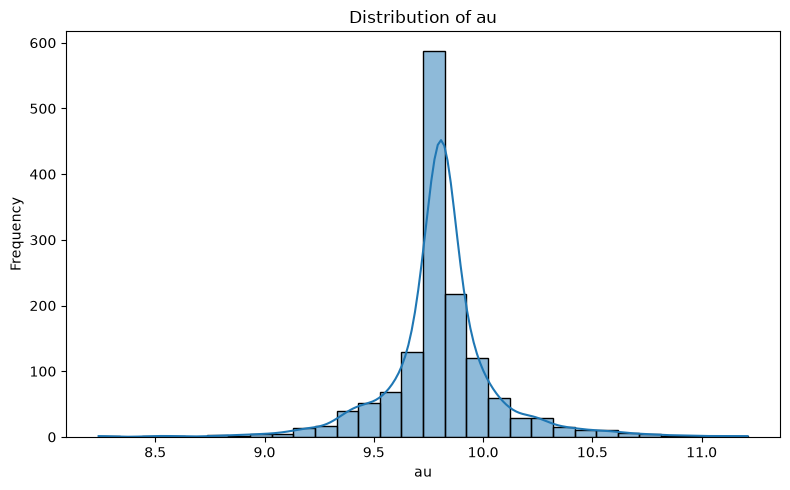

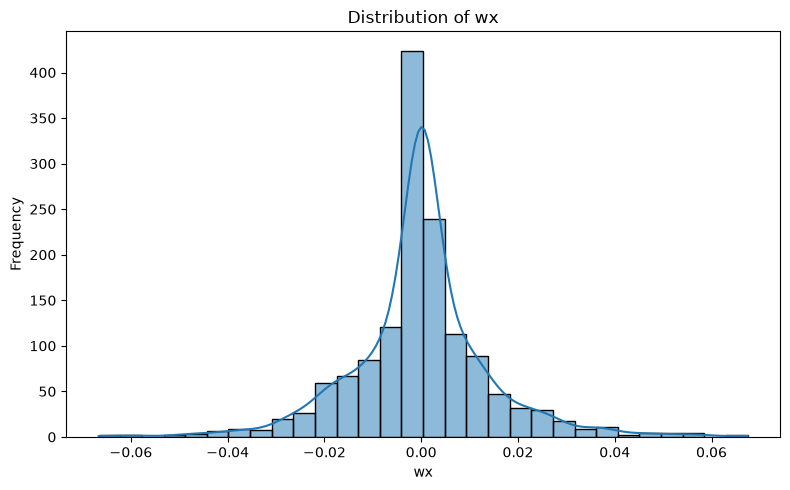

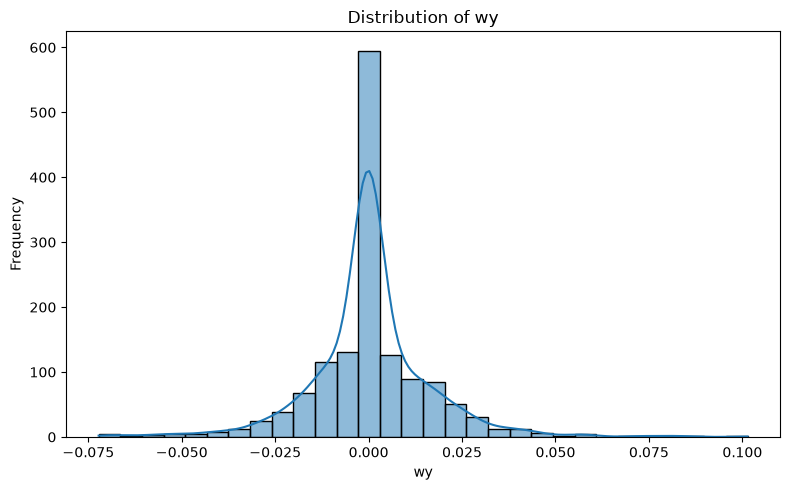

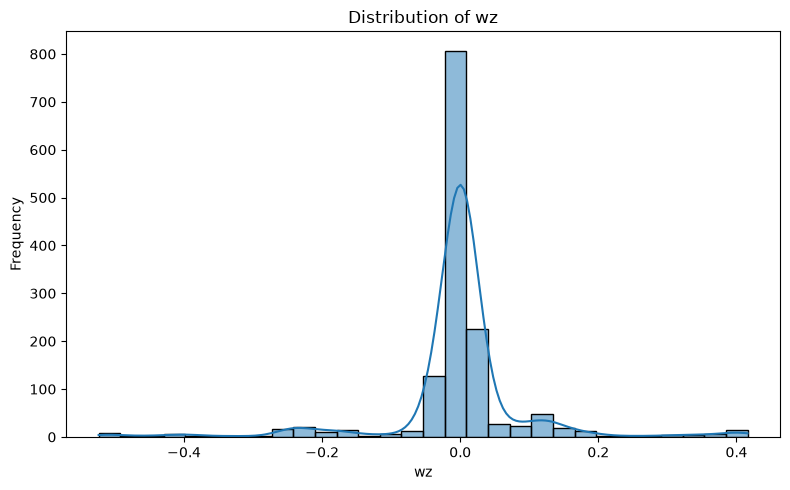

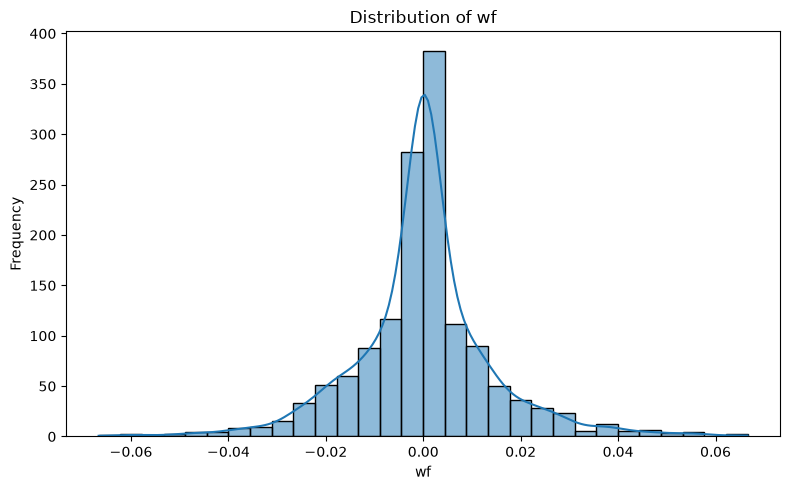

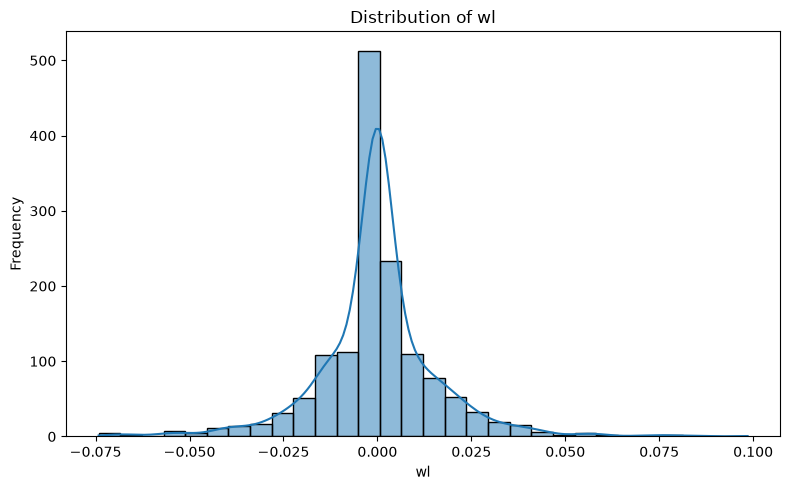

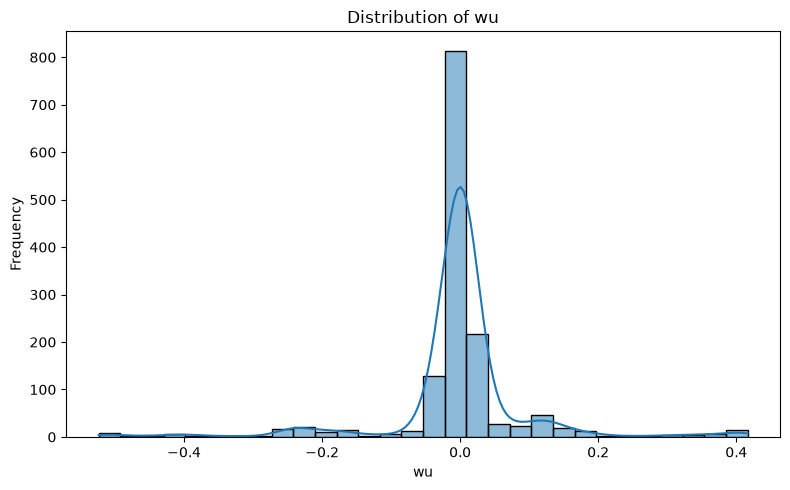

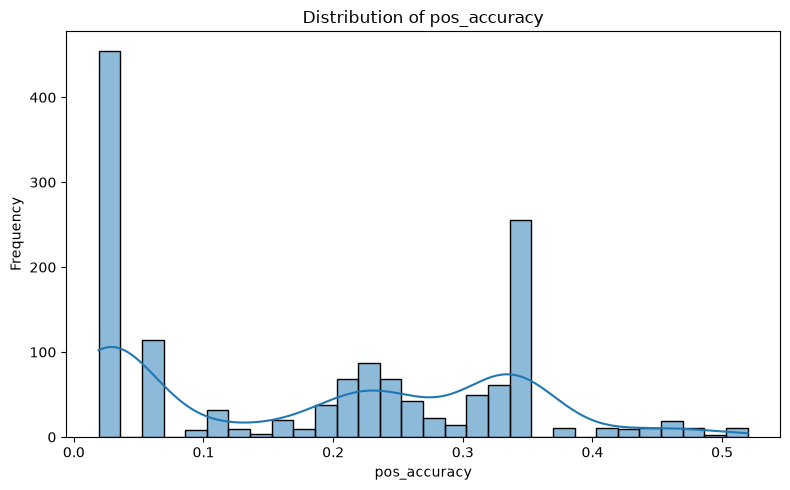

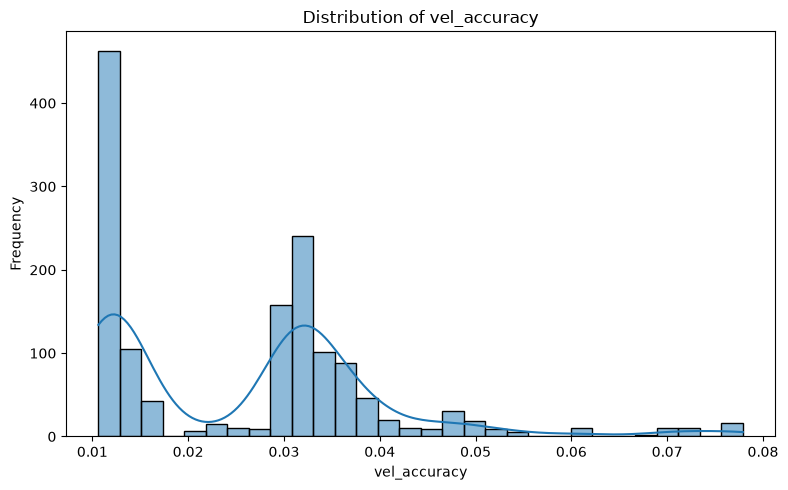

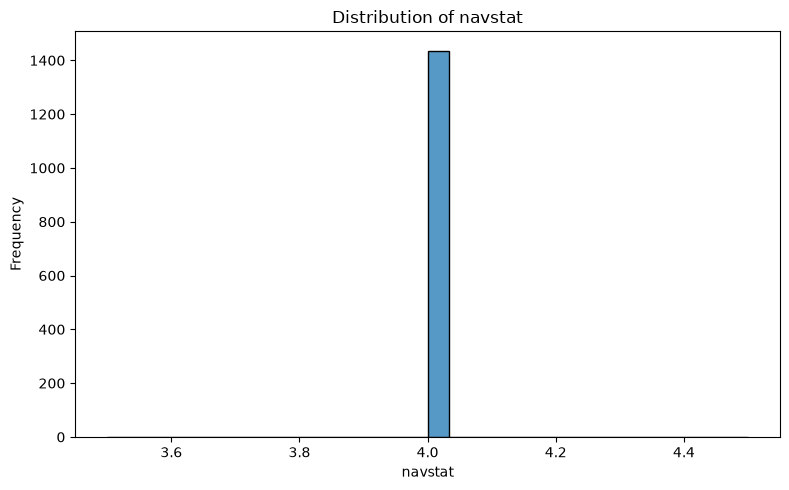

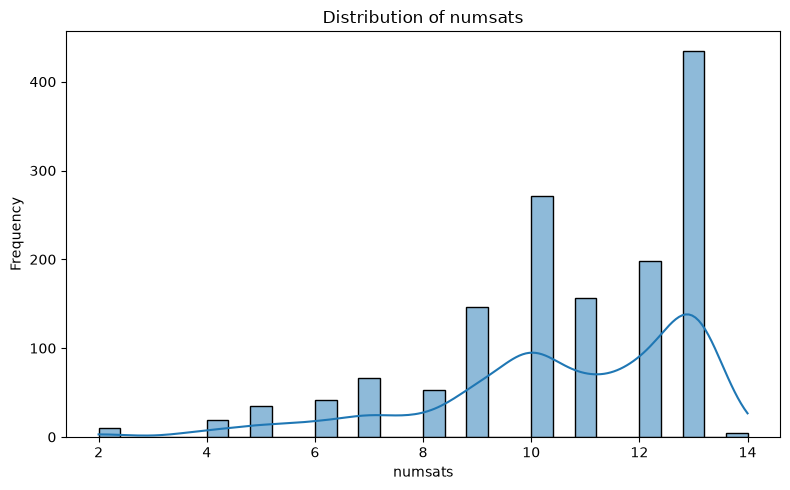

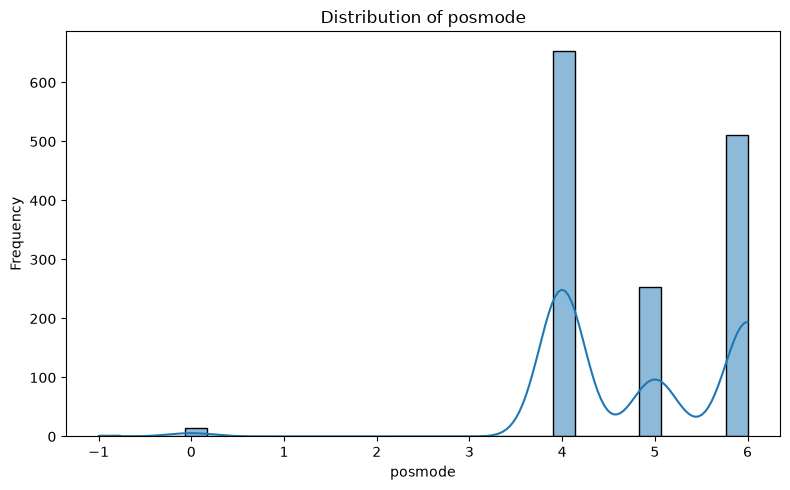

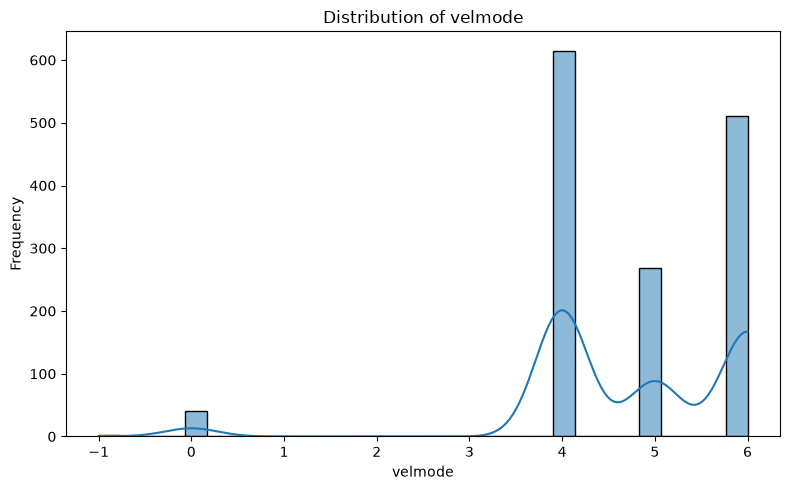

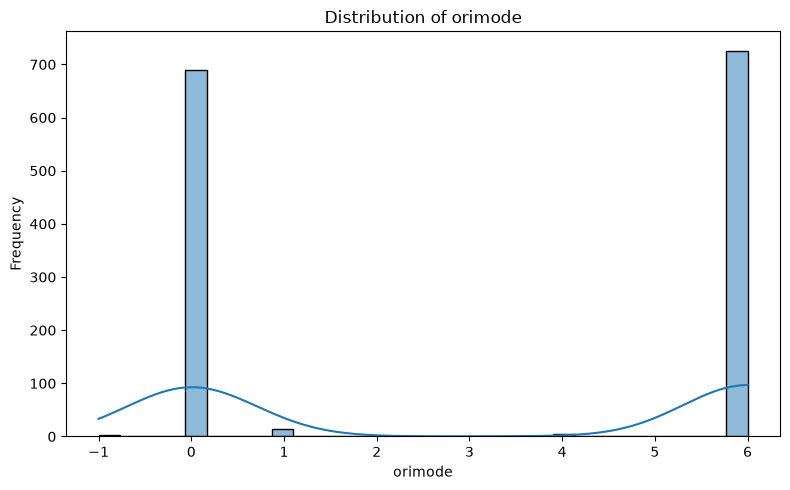

Saved and displayed 30 distribution plots.


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numeric_cols:

    # Create a new figure for each variable
    plt.figure(figsize=(8, 5))

    # Enable KDE only if the column has multiple distinct values
    use_kde = df[col].nunique(dropna=True) > 1

    # Draw the histogram and KDE
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=use_kde
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()

    # Save the figure
    file_path = figures_dir / f"hist_kde_{col}.png"
    plt.savefig(file_path, dpi=300, bbox_inches="tight")

    # Display the figure in Jupyter Notebook
    plt.show()

    # Release memory before creating the next figure
    plt.close()

print(f"Saved and displayed {len(numeric_cols)} distribution plots.")

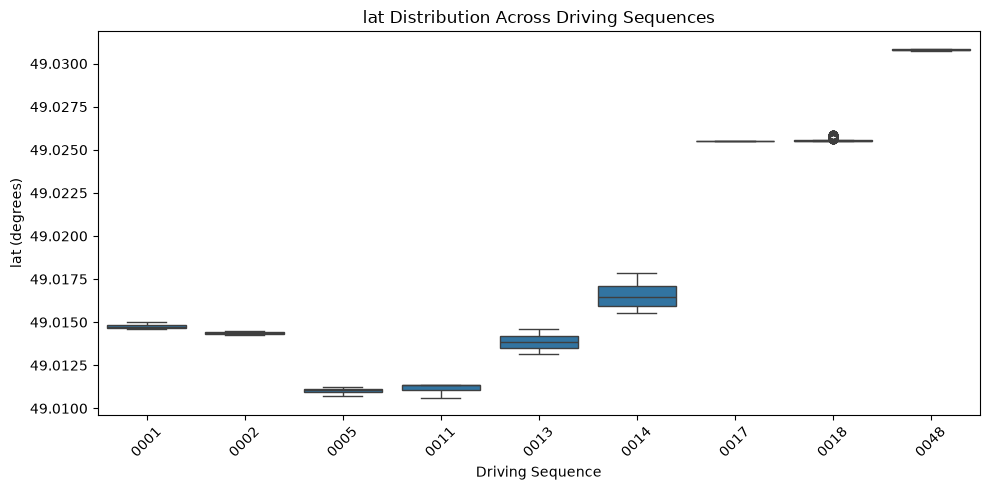

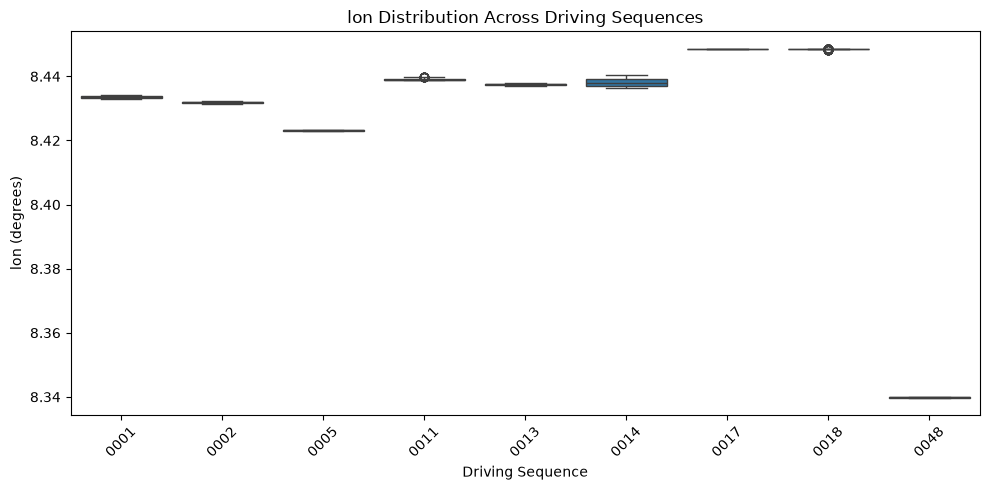

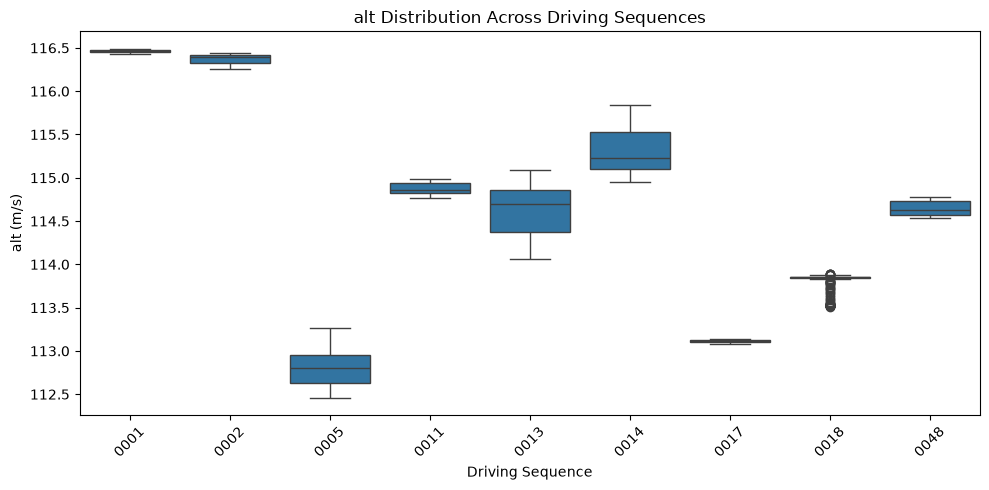

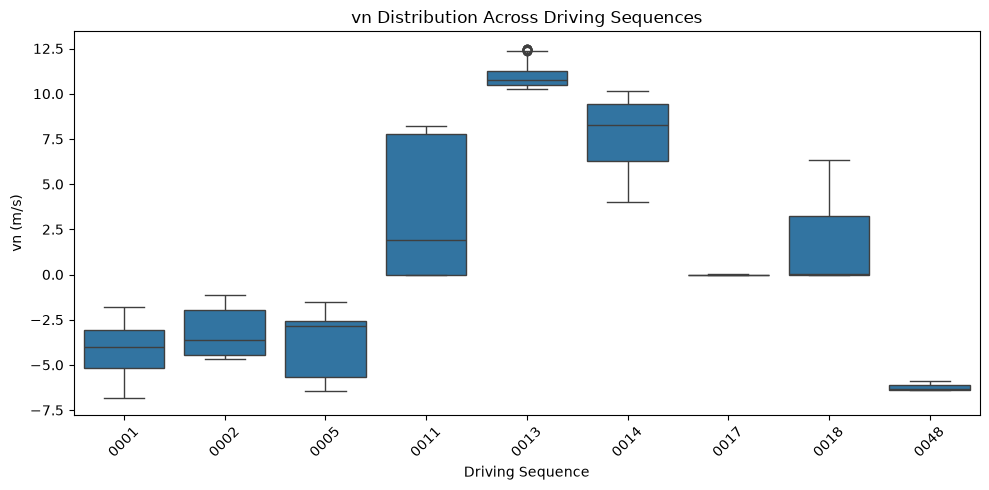

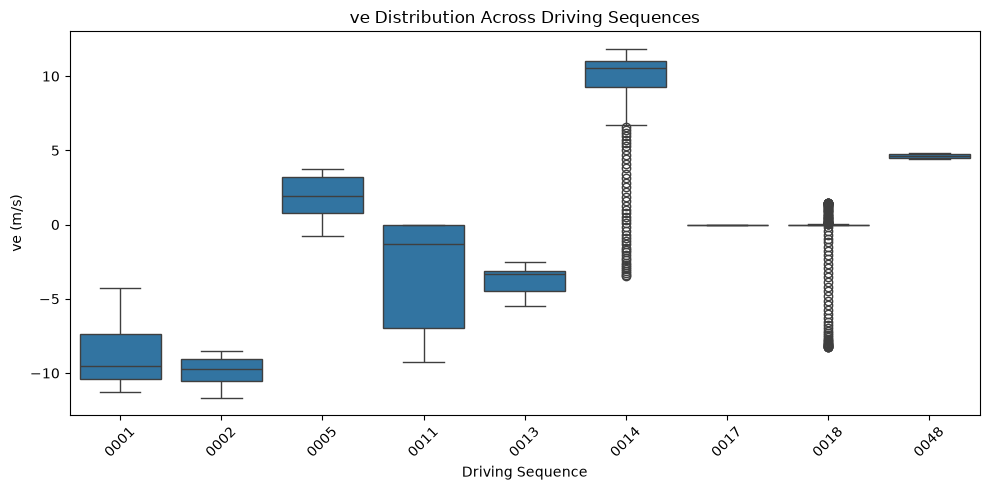

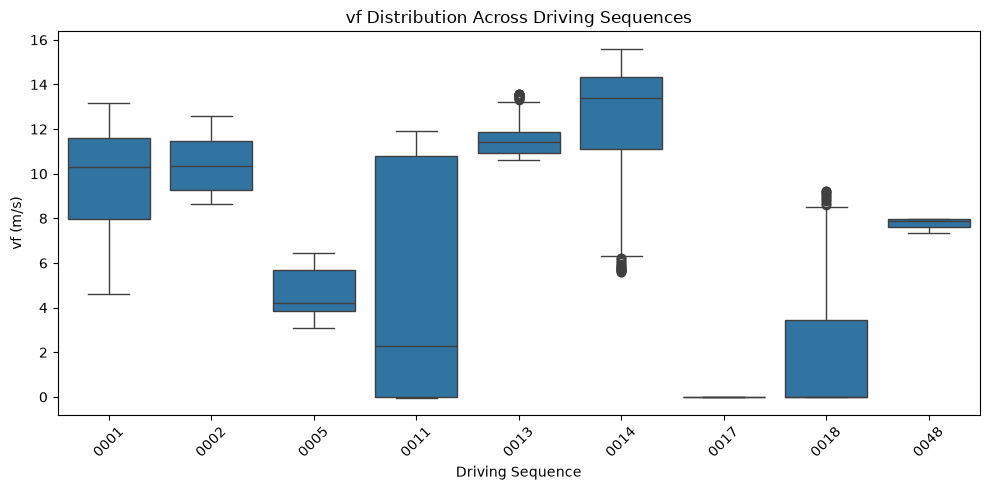

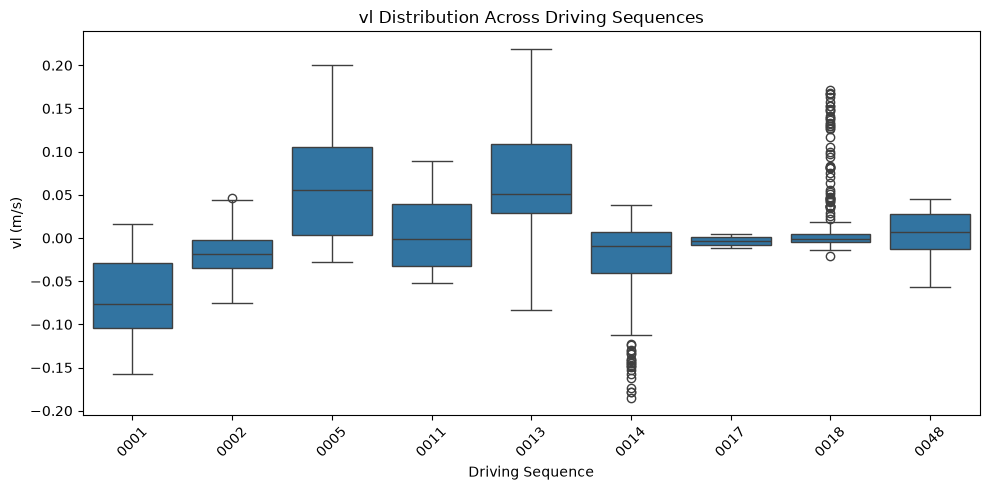

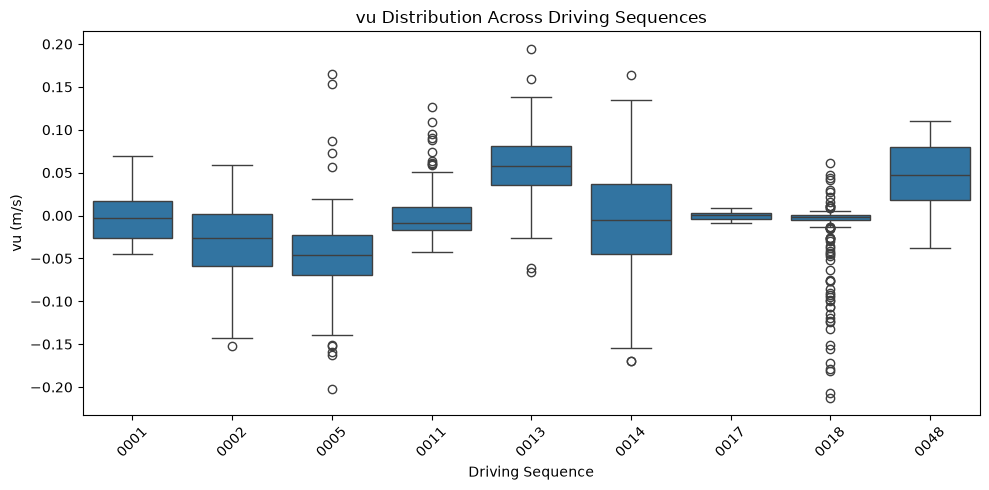

Saved 8 box plots to eda\figures


In [30]:
# Create short labels for the nine driving sequences
plot_df = df.copy()

plot_df["sequence_label"] = plot_df["date"].str.extract(
    r"drive_(\d+)_sync"
)[0]

# Sort the sequence labels numerically
sequence_order = sorted(
    plot_df["sequence_label"].dropna().unique(),
    key=int
)

# Variables to compare across sequences 
columns_to_plot = [
    "lat", "lon","alt",
    "vn", "ve", "vf", "vl", "vu"
]

# Generate and save one box plot per variable
for col in columns_to_plot:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=plot_df,
        x="sequence_label",
        y=col,
        order=sequence_order
    )

    plt.title(f"{col} Distribution Across Driving Sequences")
    plt.xlabel("Driving Sequence")

    if col in ["lat", "lon"]:
        plt.ylabel(f"{col} (degrees)")
    else:
        plt.ylabel(f"{col} (m/s)")

    plt.xticks(rotation=45)
    plt.tight_layout()

    # Save the plot
    file_path = figures_dir / f"boxplot_{col}_by_drive.png"

    plt.savefig(file_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

print(f"Saved {len(columns_to_plot)} box plots to {figures_dir}")

In [23]:
# Select numerical columns
corr_cols = df.select_dtypes(include="number").columns.tolist()

# Exclude coded navigation/status variables
excluded_cols = ["navstat", "posmode", "velmode", "orimode"]

corr_cols = [
    col for col in corr_cols
    if col not in excluded_cols
]

# Calculate Pearson correlation coefficients
correlation_matrix = df[corr_cols].corr()

print("Number of variables:", len(corr_cols))
print("Correlation matrix shape:", correlation_matrix.shape)

Number of variables: 26
Correlation matrix shape: (26, 26)


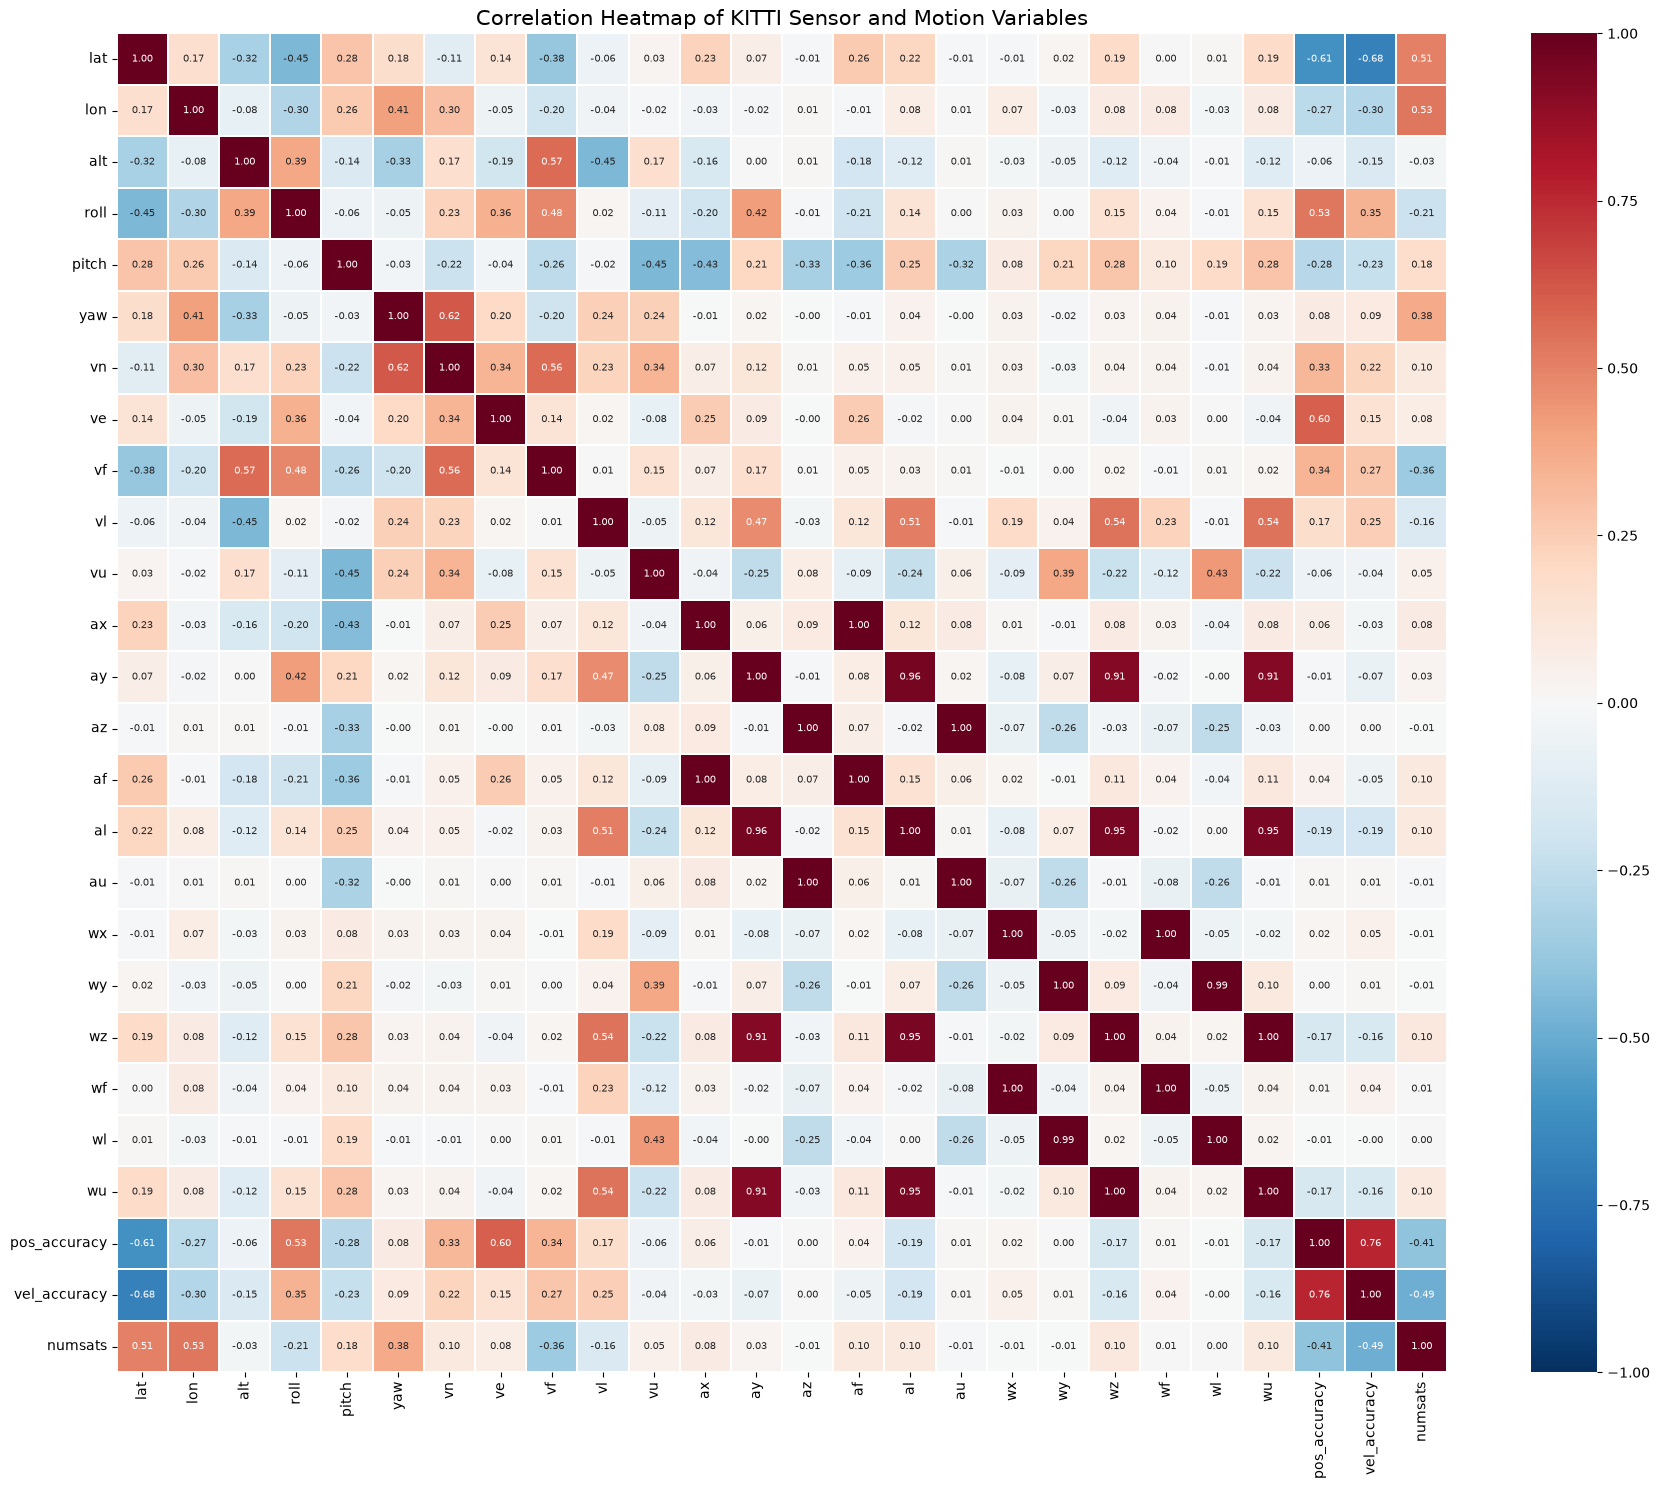

Heatmap saved to: eda\figures\correlation_heatmap.png


In [25]:
plt.figure(figsize=(18, 15))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.3,
    annot_kws={"size": 7}
)

plt.title(
    "Correlation Heatmap of KITTI Sensor and Motion Variables",
    fontsize=15
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

# Save the heatmap
heatmap_path = figures_dir / "correlation_heatmap.png"

plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Heatmap saved to:", heatmap_path)

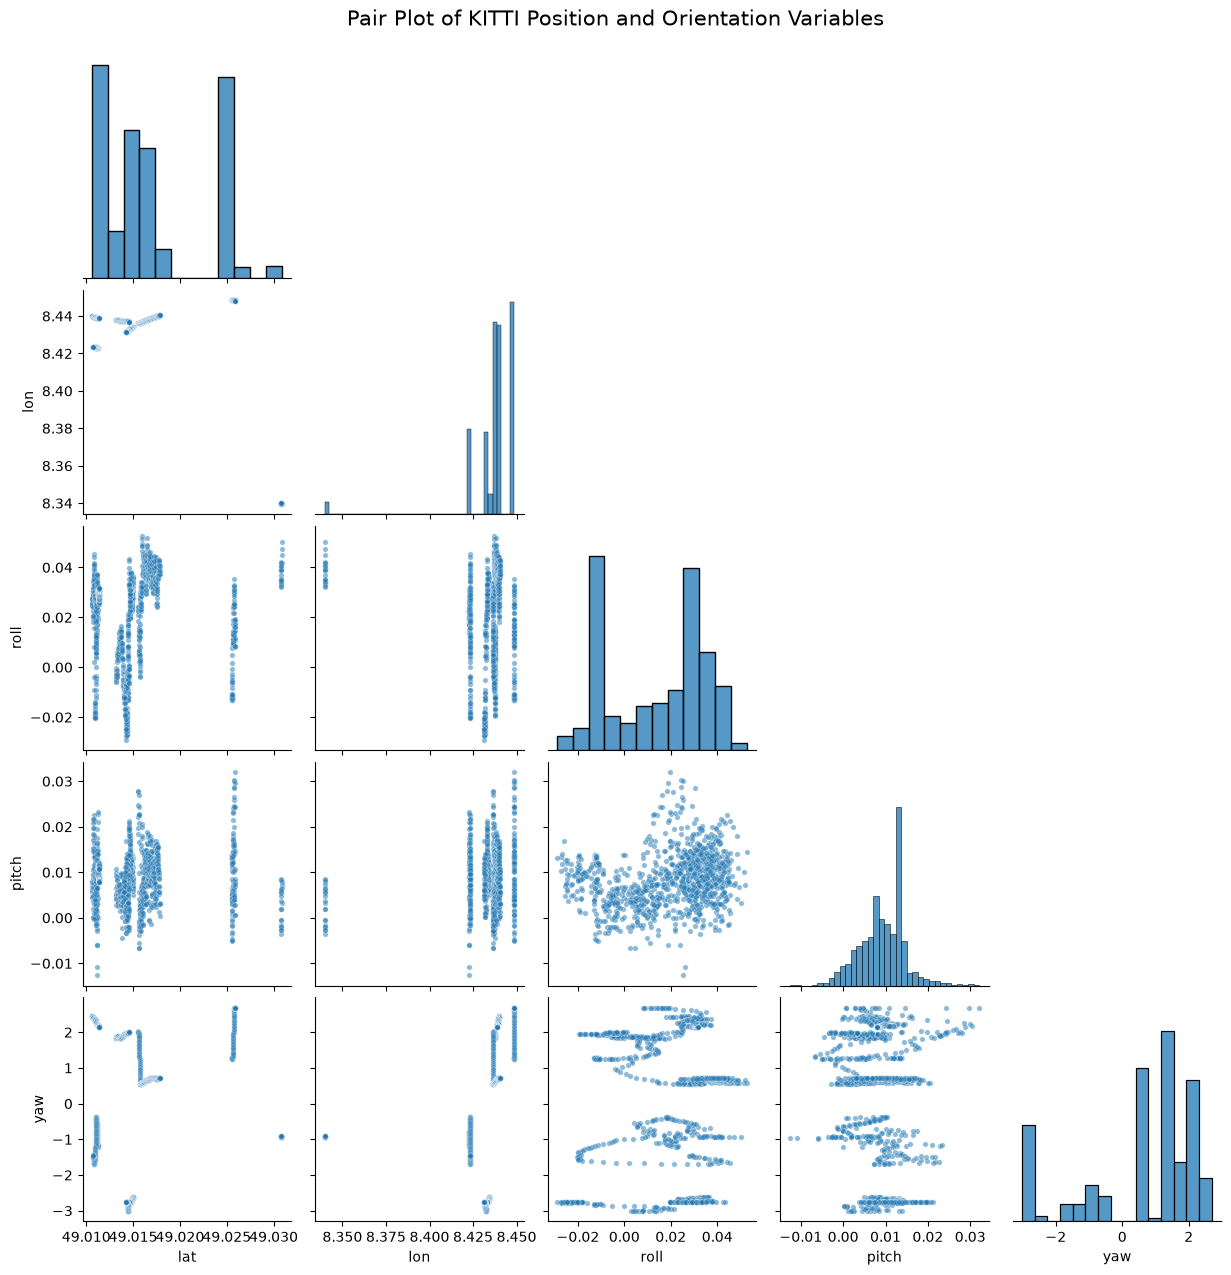

Pair plot saved to: eda\figures\pairplot_position_orientation.png


In [26]:
# Select the required variables
pair_cols = ["lat", "lon", "roll", "pitch", "yaw"]

# Create a DataFrame containing only these variables
pair_df = df[pair_cols].copy()

# Ensure all selected columns are numerical
pair_df = pair_df.apply(pd.to_numeric, errors="coerce")

# Generate the pair plot
pair_plot = sns.pairplot(
    pair_df,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 15}
)

# Add a title
pair_plot.fig.suptitle(
    "Pair Plot of KITTI Position and Orientation Variables",
    y=1.02,
    fontsize=15
)

# Save the figure
pair_plot_path = figures_dir / "pairplot_position_orientation.png"

pair_plot.fig.savefig(
    pair_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close("all")

print("Pair plot saved to:", pair_plot_path)